# Faz 5 — TabNet Mimarisi, Dikkat Maskeleri ve 6 Zorunlu Teşhis Grafiği

**Sorumlu:** Yunus Emre (TabNet & Analitik Uzmanı — Kod Savunması)

Bu notebook proje şartnamesindeki Faz 5 gereksinimlerini eksiksiz uygular:
1. **Metrik Kuralı (`Accuracy` Kesinlikle Yasak):** Proje şartnamesi gereği, veri setindeki yüksek sınıf dengesizliği (1:7.96) sebebiyle `Accuracy` (Doğruluk) metriği KESİNLİKLE YASAKTIR. Tüm model karşılaştırmaları ve teşhisler yalnızca **`Macro F1-Score`**, **`Weighted F1-Score`**, **`ROC-AUC`** ve **`PR-AUC (Average Precision)`** üzerinden gerçekleştirilir.
2. **Model 3 — Derin Tablo Mimarisi (`pytorch-tabnet`):** TabNet mimarisinin karar boyutu (`n_d`), dikkat boyutu (`n_a`) ve maskeleme tipleri (`sparsemax` vs. `entmax`) yalnızca eğitim seti içinde sızıntısız validasyonla karşılaştırılır; en iyi mimari seçilerek erken durdurma (early stopping) ve kayıp eğrileri optimize edilir.
3. **TabNet Dikkat Maskeleri (`Explain` Mekanizması):** `tabnet.explain()` ile her karar adımındaki seyrek dikkat maskeleri (`sparse attention masks`) ve küresel özellik önemleri (`feature_importances_`) çıkarılır.
4. **6 Zorunlu Teşhis Grafiği (`reports/figures/`):**
   - **Grafik 1:** `missingno` ile eksik veri korelasyon ısı haritası ve dendrogramı (`01_missingness_heatmap_dendrogram.png`).
   - **Grafik 2:** Gerçek vs. Sentetik (`SMOTE` & `CTGAN`) pozitif sınıf için üst üste binen KDE dağılımları (`02_real_vs_synthetic_distributions.png`).
   - **Grafik 3:** Gerçek ve sentetik korelasyon yapısının korunduğunu gösteren mutlak korelasyon fark matrisi (`|Corr_Real - Corr_Synthetic|`) (`03_correlation_difference_matrix.png`).
   - **Grafik 4:** TabNet adım bazlı dikkat maskeleri ile GBDT özellik önemlerinin yan yana karşılaştırması (`04_tabnet_masks_vs_gbdt_importance.png`).
   - **Grafik 5:** Üç modelin (`Perceptron`, `GBDT`, `TabNet`) tek figürde birleşik `ROC-AUC` ve `Precision-Recall (PR-AUC)` eğrileri (`05_combined_roc_and_pr_curves.png`).
   - **Grafik 6:** Üç modelin yan yana satır bazlı normalize edilmiş Karmaşıklık Matrisleri (`Confusion Matrix Grid`) (`06_normalized_confusion_matrix_grid.png`).
   - **Ek Grafik:** TabNet eğitim ve doğrulama kayıp eğrileri (`07_tabnet_training_loss_curves.png`).
5. **Uçtan Uca Model Karşılaştırması:** `Perceptron` (Referans), `LightGBM` (GBDT + Optuna) ve `TabNet` (Derin Tablo) modellerinin 4 şartname metriği ve klinik pozitif yakalama oranı (sensitivity) üzerinden kapsamlı analizi.


In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import time
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

from src import config
from src import models
from src import plots
from src import tabnet_model as tm

print("Faz 5 Ortamı Başarıyla Hazırlandı:")
print(f"PyTorch Sürümü   : {torch.__version__}")
print(f"Proje Kök Dizini : {config.PROJECT_ROOT.name}")
print(f"Rastgele Tohum   : {config.RANDOM_STATE}")


Faz 5 Ortamı Başarıyla Hazırlandı:
PyTorch Sürümü   : 2.15.0
Proje Kök Dizini : datascience
Rastgele Tohum   : 42


## 1. Faz 2 ve Faz 4 Çıktılarının Yüklenmesi

Faz 2'de MICE ile eksik verileri doldurulmuş, aykırı değerleri kırpılmış ve ölçeklenmiş 154 boyutlu veri setleri (`X_train`, `X_test`, `y_train`, `y_test`), sentetik pozitif örnekler (`SMOTE` & `CTGAN`) ve Faz 4'te Ertuğrul tarafından eğitilip kaydedilen model çıktıları (`faz4_outputs.pkl`) ile Faz 5 TabNet çıktıları (`tabnet_outputs.pkl`) yüklenir.


In [2]:
t0 = time.perf_counter()
X_train = pd.read_pickle(config.PROCESSED_DATA_DIR / "X_train.pkl")
X_test = pd.read_pickle(config.PROCESSED_DATA_DIR / "X_test.pkl")
y_train = pd.read_pickle(config.PROCESSED_DATA_DIR / "y_train.pkl")
y_test = pd.read_pickle(config.PROCESSED_DATA_DIR / "y_test.pkl")
df_missing = pd.read_pickle(config.PROCESSED_DATA_DIR / "df_missing.pkl")
X_syn_smote_pos = pd.read_pickle(
    config.PROCESSED_DATA_DIR / "X_syn_smote_pos.pkl"
)
X_syn_ctgan_pos = pd.read_pickle(
    config.PROCESSED_DATA_DIR / "X_syn_ctgan_pos.pkl"
)
faz4_data = models.load_faz4_outputs()
faz5_data = tm.load_tabnet_outputs()

print(f"Veriler ve model çıktıları yüklendi ({time.perf_counter() - t0:.2f} s):")
print(f"  * X_train boyutu : {X_train.shape}")
print(f"  * X_test boyutu  : {X_test.shape}")
print(f"  * Sınıf oranı (y_train == 1): %{(y_train == 1).mean() * 100:.2f}")
print(f"  * Sınıf oranı (y_test == 1) : %{(y_test == 1).mean() * 100:.2f}")
print(f"  * Faz 4 modelleri: {list(faz4_data['comparison_df']['Model'])}")


Veriler ve model çıktıları yüklendi (0.20 s):
  * X_train boyutu : (81412, 154)
  * X_test boyutu  : (20354, 154)
  * Sınıf oranı (y_train == 1): %11.16
  * Sınıf oranı (y_test == 1) : %11.16
  * Faz 4 modelleri: ['Perceptron (Baseline - Tuned eta0)', 'LightGBM (Baseline - Varsayılan)', 'LightGBM (Optuna + 5-Fold Stratified CV)']


## 2. Model 3 — Derin Tablo Mimarisi TabNet (pytorch-tabnet)

TabNet (Arik & Pfister, Google Cloud AI Research), tablo verileri için özel olarak tasarlanmış derin öğrenme mimarisidir:
- **Sequential Attention Mechanism (Ardışık Dikkat):** Karar adımlarında (`n_steps=3`) hangi özelliklerin seçileceğini belirler.
- **Sparse Selection (Seyrek Seçim):** `Sparsemax` veya `Entmax` aktivasyonları kullanılarak gereksiz özellikler sıfıra indirgenir.
- **Prior Scale Term ($\gamma$):** Önceki adımlarda seçilen özelliklerin tekrar seçilmesini cezalandırarak modelin veri setinin farklı boyutlarından bilgi toplamasını sağlar.
- **Feature Transformer:** Paylaşılan (shared) ve adıma özgü (step-dependent) GLU (Gated Linear Unit) blokları ve Ghost Batch Normalization ile doğrusal olmayan ilişkileri öğrenir.
- **Optimizasyon:** Aşırı öğrenmeyi (overfitting) engellemek için erken durdurma (`early stopping`, `patience=5`) ve ağırlıklı kayıp fonksiyonu (`weights=1`) ile eğitilir.


In [3]:
arch_df = faz5_data["arch_comparison_df"]
best_cfg = faz5_data["best_cfg"]

print("TabNet Mimari Konfigürasyonları Karşılaştırması:")
print(f"En Başarılı Konfigürasyon: {best_cfg['label']}")
assert "Accuracy" not in arch_df.columns, "KURAL İHLALİ: Accuracy hesaplanamaz!"
arch_df.round(4)


TabNet Mimari Konfigürasyonları Karşılaştırması:
En Başarılı Konfigürasyon: Nd=16, Na=16 (Entmax)


,Yapılandırma,n_d,n_a,mask_type,Bileşik_Skor,Macro_F1,Weighted_F1,ROC_AUC,PR_AUC
0,"Nd=16, Na=16 (Entmax)",16,16,entmax,0.4910,0.5138,0.6974,0.6961,0.2401
1,"Nd=16, Na=16 (Sparsemax)",16,16,sparsemax,0.4874,0.5098,0.6903,0.6954,0.2346
2,"Nd=8, Na=8 (Sparsemax)",8,8,sparsemax,0.4754,0.4943,0.6689,0.6856,0.2273


## 3. En İyi TabNet Modelinin Test Seti (`X_test`) Üzerinde Değerlendirilmesi

Seçilen en iyi TabNet mimarisi (`Nd=16, Na=16, Entmax`) hiç görülmemiş 20.354 satırlık test seti (`X_test`) üzerinde değerlendirilir.
Yüksek sınıf dengesizliğinde (`1:7.96`) yanıltıcı olan `Accuracy` yerine, şartname gereği zorunlu 4 metrik ve normalize karmaşıklık matrisi raporlanır.


In [4]:
tabnet_metrics = faz5_data["metrics"]
tabnet_cm_norm = faz5_data["confusion_matrix_norm"]

print("TabNet X_test Performans Metrikleri:")
for k, v in tabnet_metrics.items():
    print(f"  - {k:<15}: {v:.4f}")

print()
print("Normalize Edilmiş Karmaşıklık Matrisi (TabNet):")
cm_df = pd.DataFrame(
    tabnet_cm_norm,
    index=["Gerçek: Negatif (0)", "Gerçek: <30g (1)"],
    columns=["Tahmin: Negatif (0)", "Tahmin: <30g (1)"],
)
cm_df.applymap(lambda x: f"%{x * 100:.2f}")


Cell execution error: unterminated string literal (detected at line 8) (<string>, line 8)


## 4. TabNet Açıklanabilirlik (`Explain`), Dikkat Maskeleri ve Özellik Önemi

TabNet'in standart sinir ağlarına göre en büyük üstünlüğü yerleşik açıklanabilirlik mekanizmasıdır (`explain()`):
- **Adım Bazlı Maskeler:** Her karar adımında hangi özelliklerin ön plana çıktığı `step_masks_df` üzerinden incelenir.
- **Toplu Klinik Özellik Önemleri:** Kodlanmış 154 özellik, ham veri setindeki 42 klinik değişken altında toplanarak GBDT ağaç modelleriyle karşılaştırılabilir hale getirilir.


In [5]:
explain_dict = faz5_data["explain_dict"]
tabnet_imp_42 = faz5_data["tabnet_imp_42"]
step_masks_df = explain_dict["step_masks_df"]

print("TabNet Karar Adımları (Step Attention Masks) - En Etkin 10 Değişken:")
top10_idx = step_masks_df.mean(axis=1).sort_values(ascending=False).head(10).index
display(step_masks_df.loc[top10_idx].round(4))

print()
print("TabNet Toplu Klinik Değişken Önemleri (Top 10):")
tabnet_imp_42.head(10)[["Özellik", "Önem_Skoru", "Önem_%"]].round(4)


Cell execution error: unterminated string literal (detected at line 9) (<string>, line 9)


## 5. Proje Şartnamesindeki 6 Zorunlu Teşhis Grafiği ve Kayıp Eğrileri

Hocanın resmi şartnamesinde istenen 6 zorunlu görselleştirme ve TabNet kayıp eğrisi yüksek çözünürlüklü (300 DPI) olarak `reports/figures/` dizinine kaydedilmiştir. Aşağıda her bir grafik ve klinik/teknik yorumları sunulmaktadır:

1. **Grafik 1 (`01_missingness_heatmap_dendrogram.png`):** Ham verideki eksiklik örüntülerini ve değişkenlerin birlikte eksik olma korelasyonunu gösterir (`missingno` heatmap & dendrogram).
2. **Grafik 2 (`02_real_vs_synthetic_distributions.png`):** En önemli klinik özellikler için Gerçek Pozitif vs. SMOTE vs. CTGAN sentetik dağılımlarını üst üste binmiş KDE ile karşılaştırır.
3. **Grafik 3 (`03_correlation_difference_matrix.png`):** Gerçek ve sentetik veriler arasındaki korelasyon yapısının korunduğunu gösteren mutlak korelasyon farkı matrisidir ($|Corr_{Gerçek} - Corr_{Sentetik}|$).
4. **Grafik 4 (`04_tabnet_masks_vs_gbdt_importance.png`):** TabNet'in karar adımlarında seçtiği dikkat maskeleri ile GBDT ağaç modelinin özellik önemlerini yan yana karşılaştırır.
5. **Grafik 5 (`05_combined_roc_and_pr_curves.png`):** Üç modelin (`Perceptron`, `GBDT`, `TabNet`) tek bir figürde birleşik ROC-AUC ve Precision-Recall (PR-AUC) eğrilerini gösterir.
6. **Grafik 6 (`06_normalized_confusion_matrix_grid.png`):** Üç modelin satır bazlı normalize edilmiş Karmaşıklık Matrisleri Grid'idir.
7. **Ek Grafik (`07_tabnet_training_loss_curves.png`):** TabNet derin öğrenme modelinin epoch bazlı eğitim ve doğrulama kayıp eğrileridir.



Grafik 1: Eksik Veri Isı Haritası ve Dendrogramı
<IPython.core.display.Image object>

Grafik 2: Gerçek vs. Sentetik (SMOTE & CTGAN) Dağılımları
<IPython.core.display.Image object>

Grafik 3: Gerçek vs Sentetik Korelasyon Fark Matrisi
<IPython.core.display.Image object>

Grafik 4: TabNet Dikkat Maskeleri vs. GBDT Özellik Önemi
<IPython.core.display.Image object>

Grafik 5: Birleşik ROC-AUC ve PR-AUC Eğrileri (3 Model)
<IPython.core.display.Image object>

Grafik 6: 3'lü Normalize Karmaşıklık Matrisleri Grid'i
<IPython.core.display.Image object>

Ek Grafik: TabNet Eğitim ve Doğrulama Kayıp Eğrileri
<IPython.core.display.Image object>


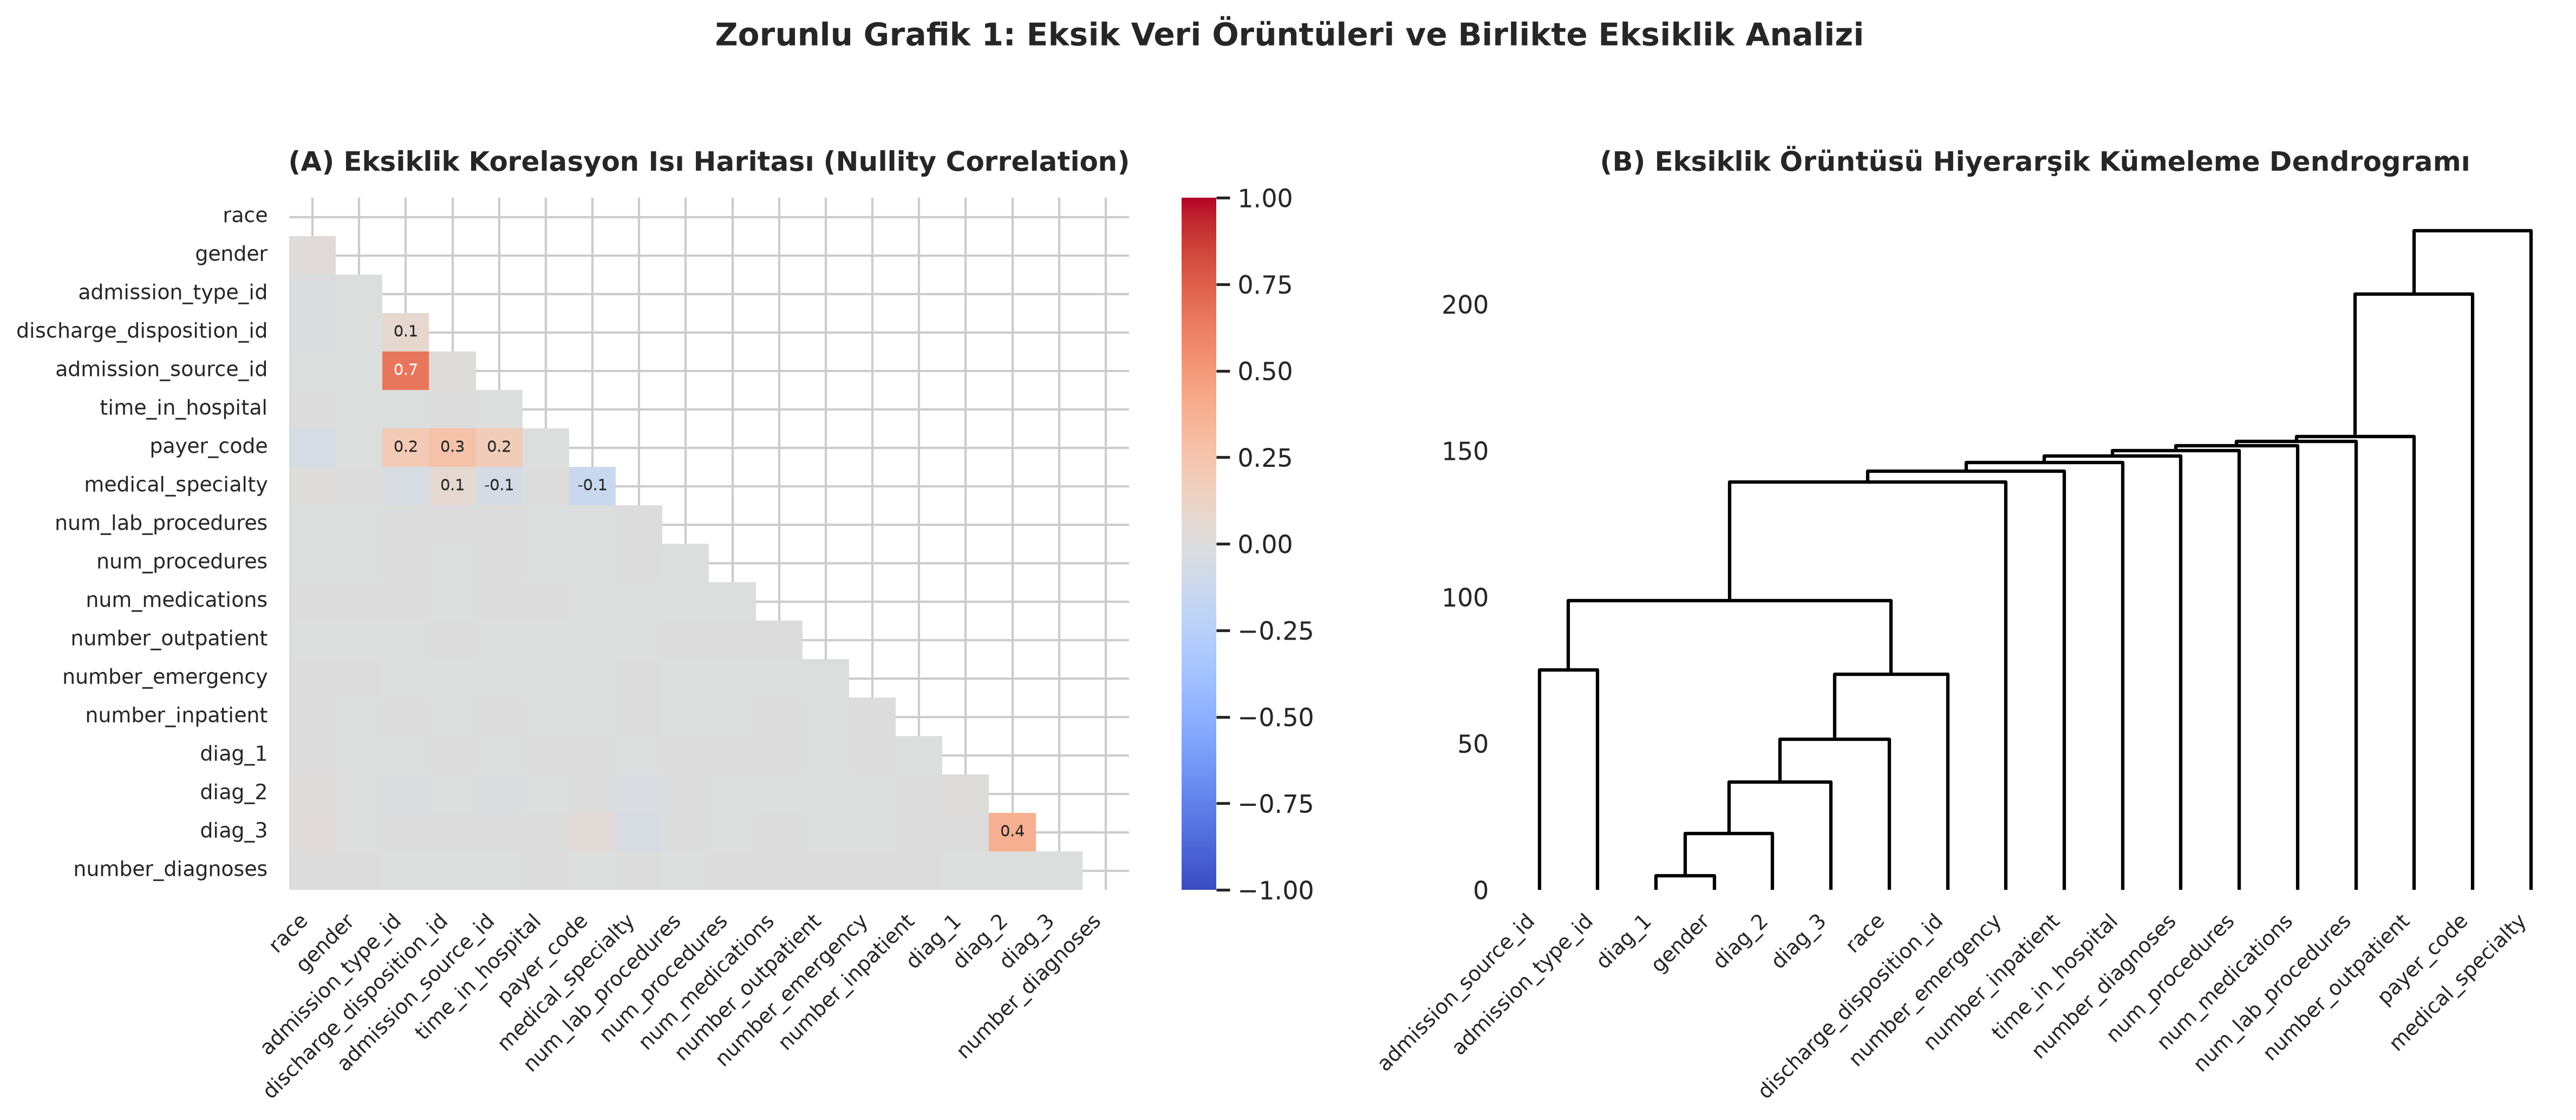

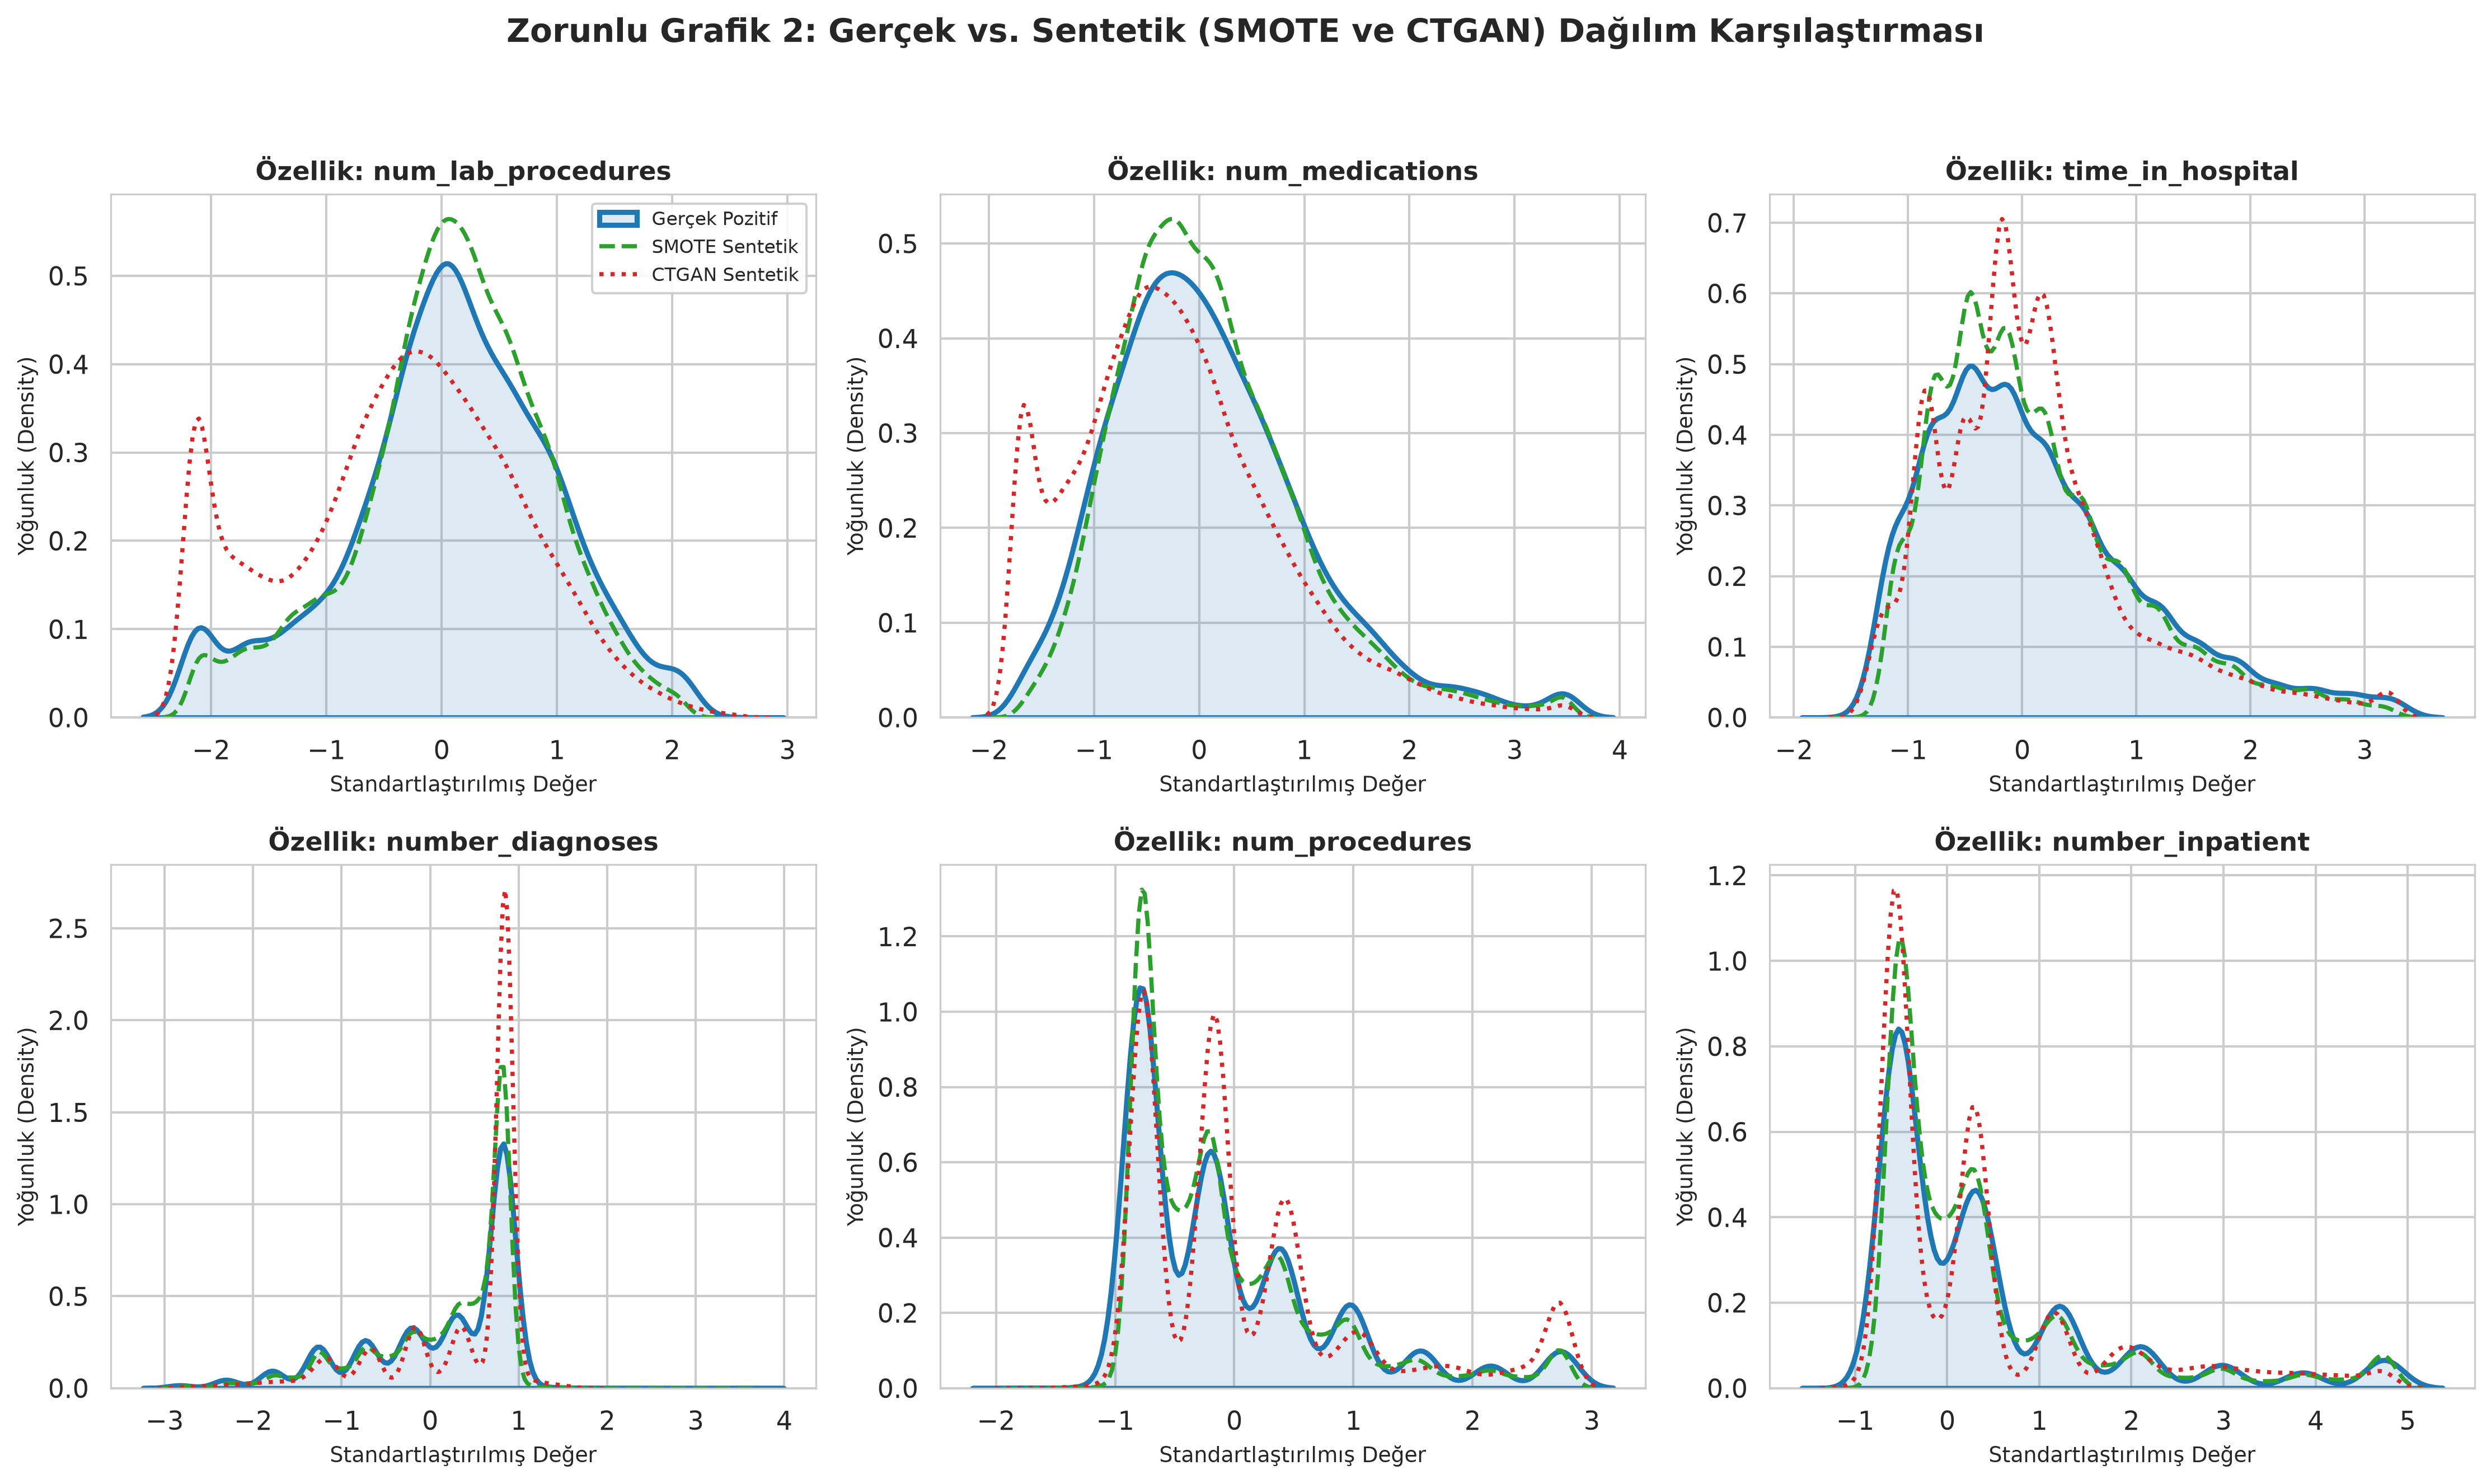

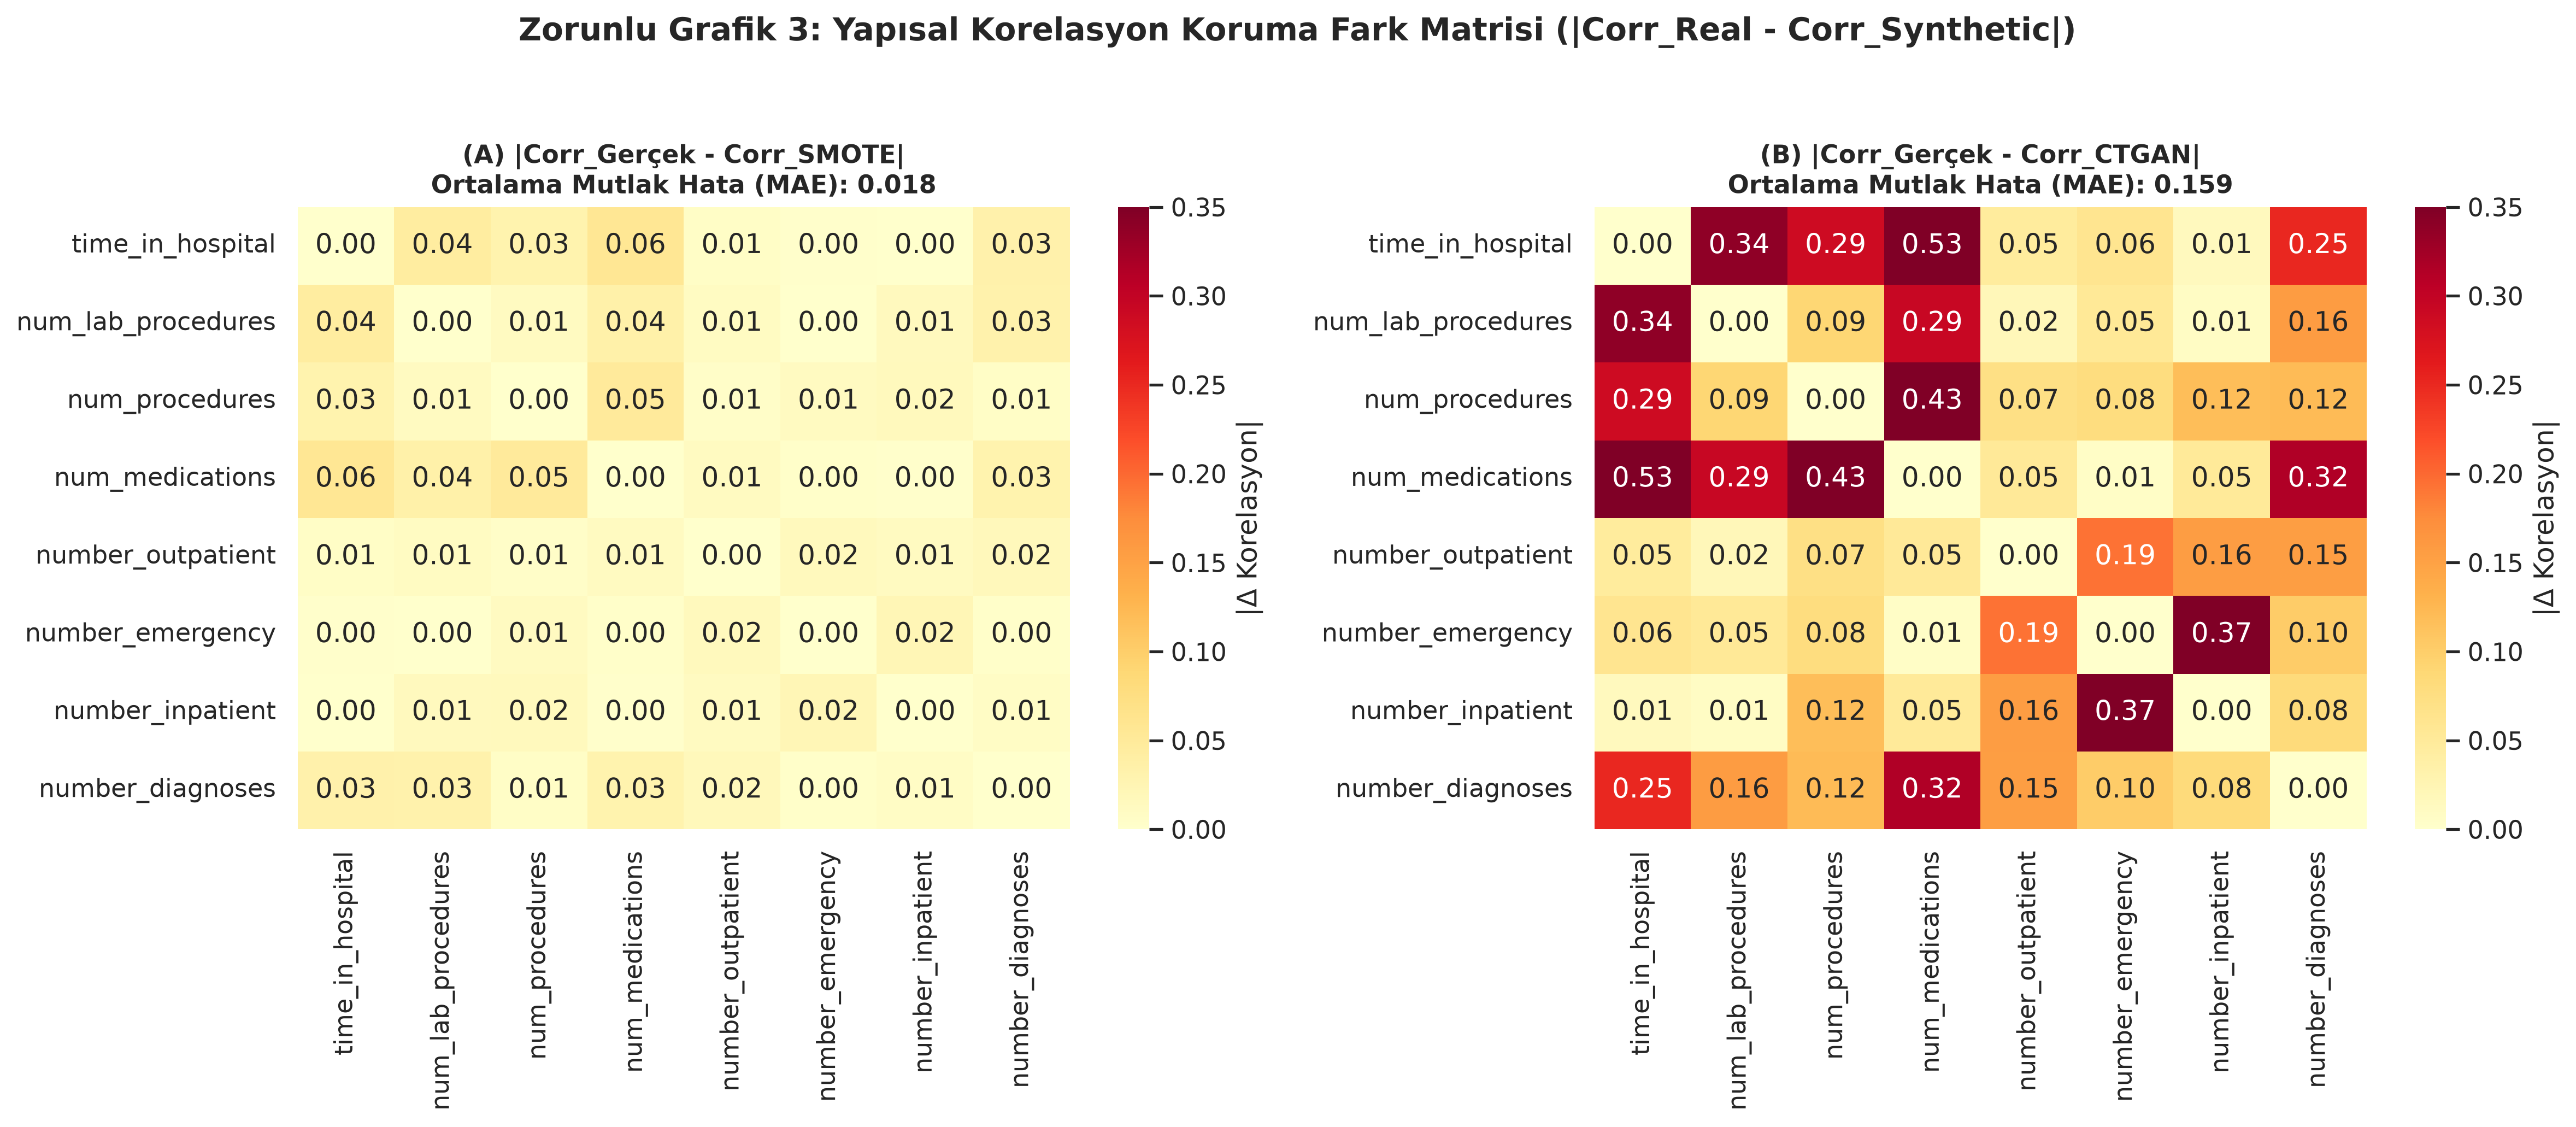

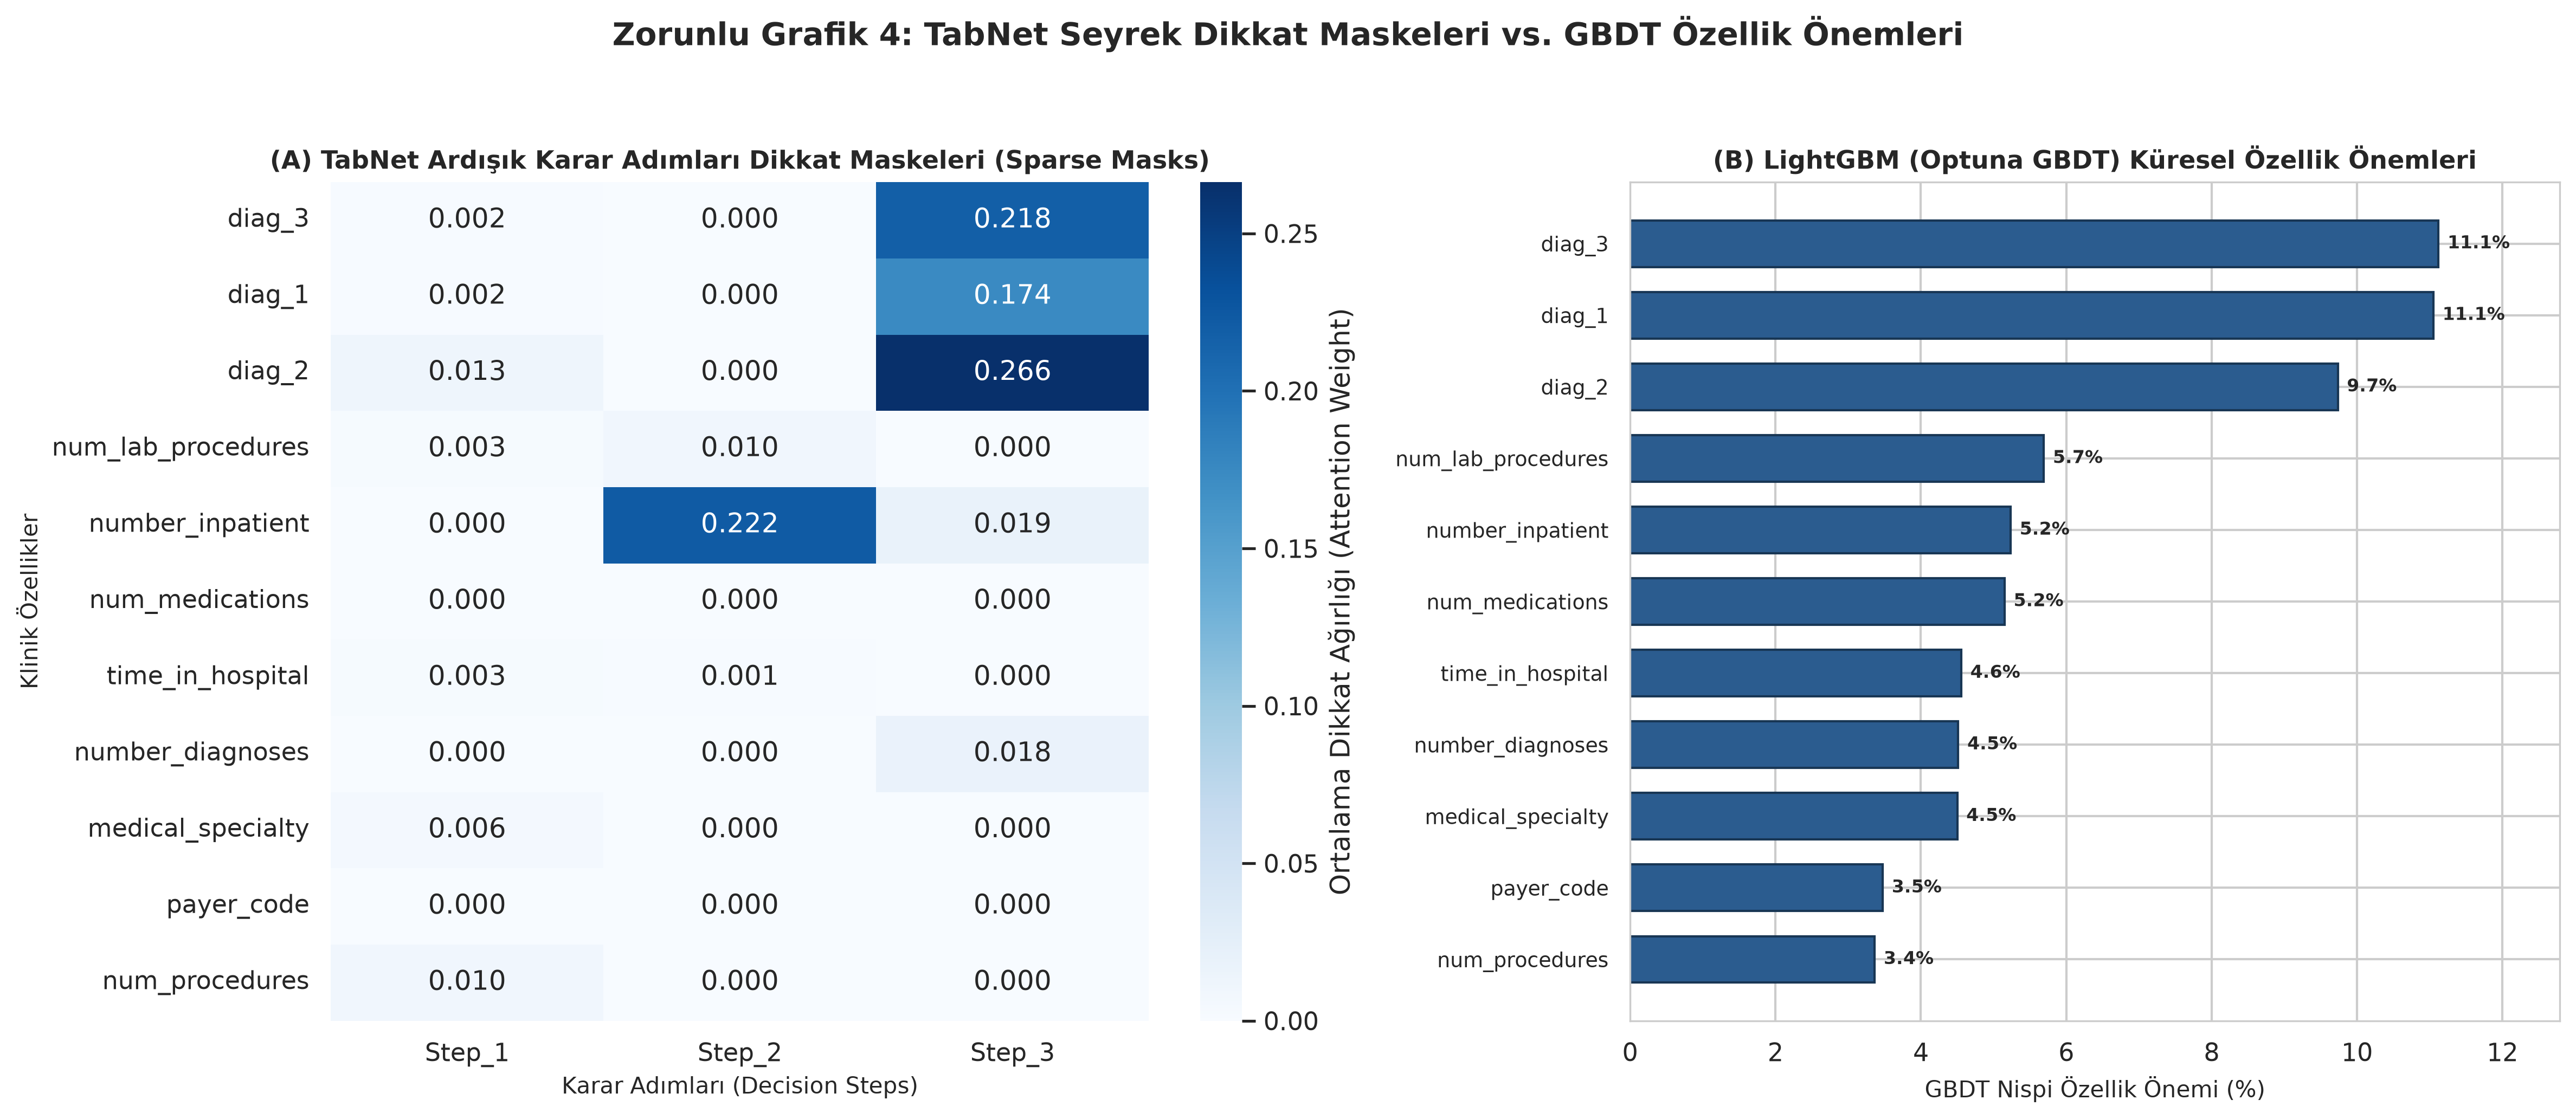

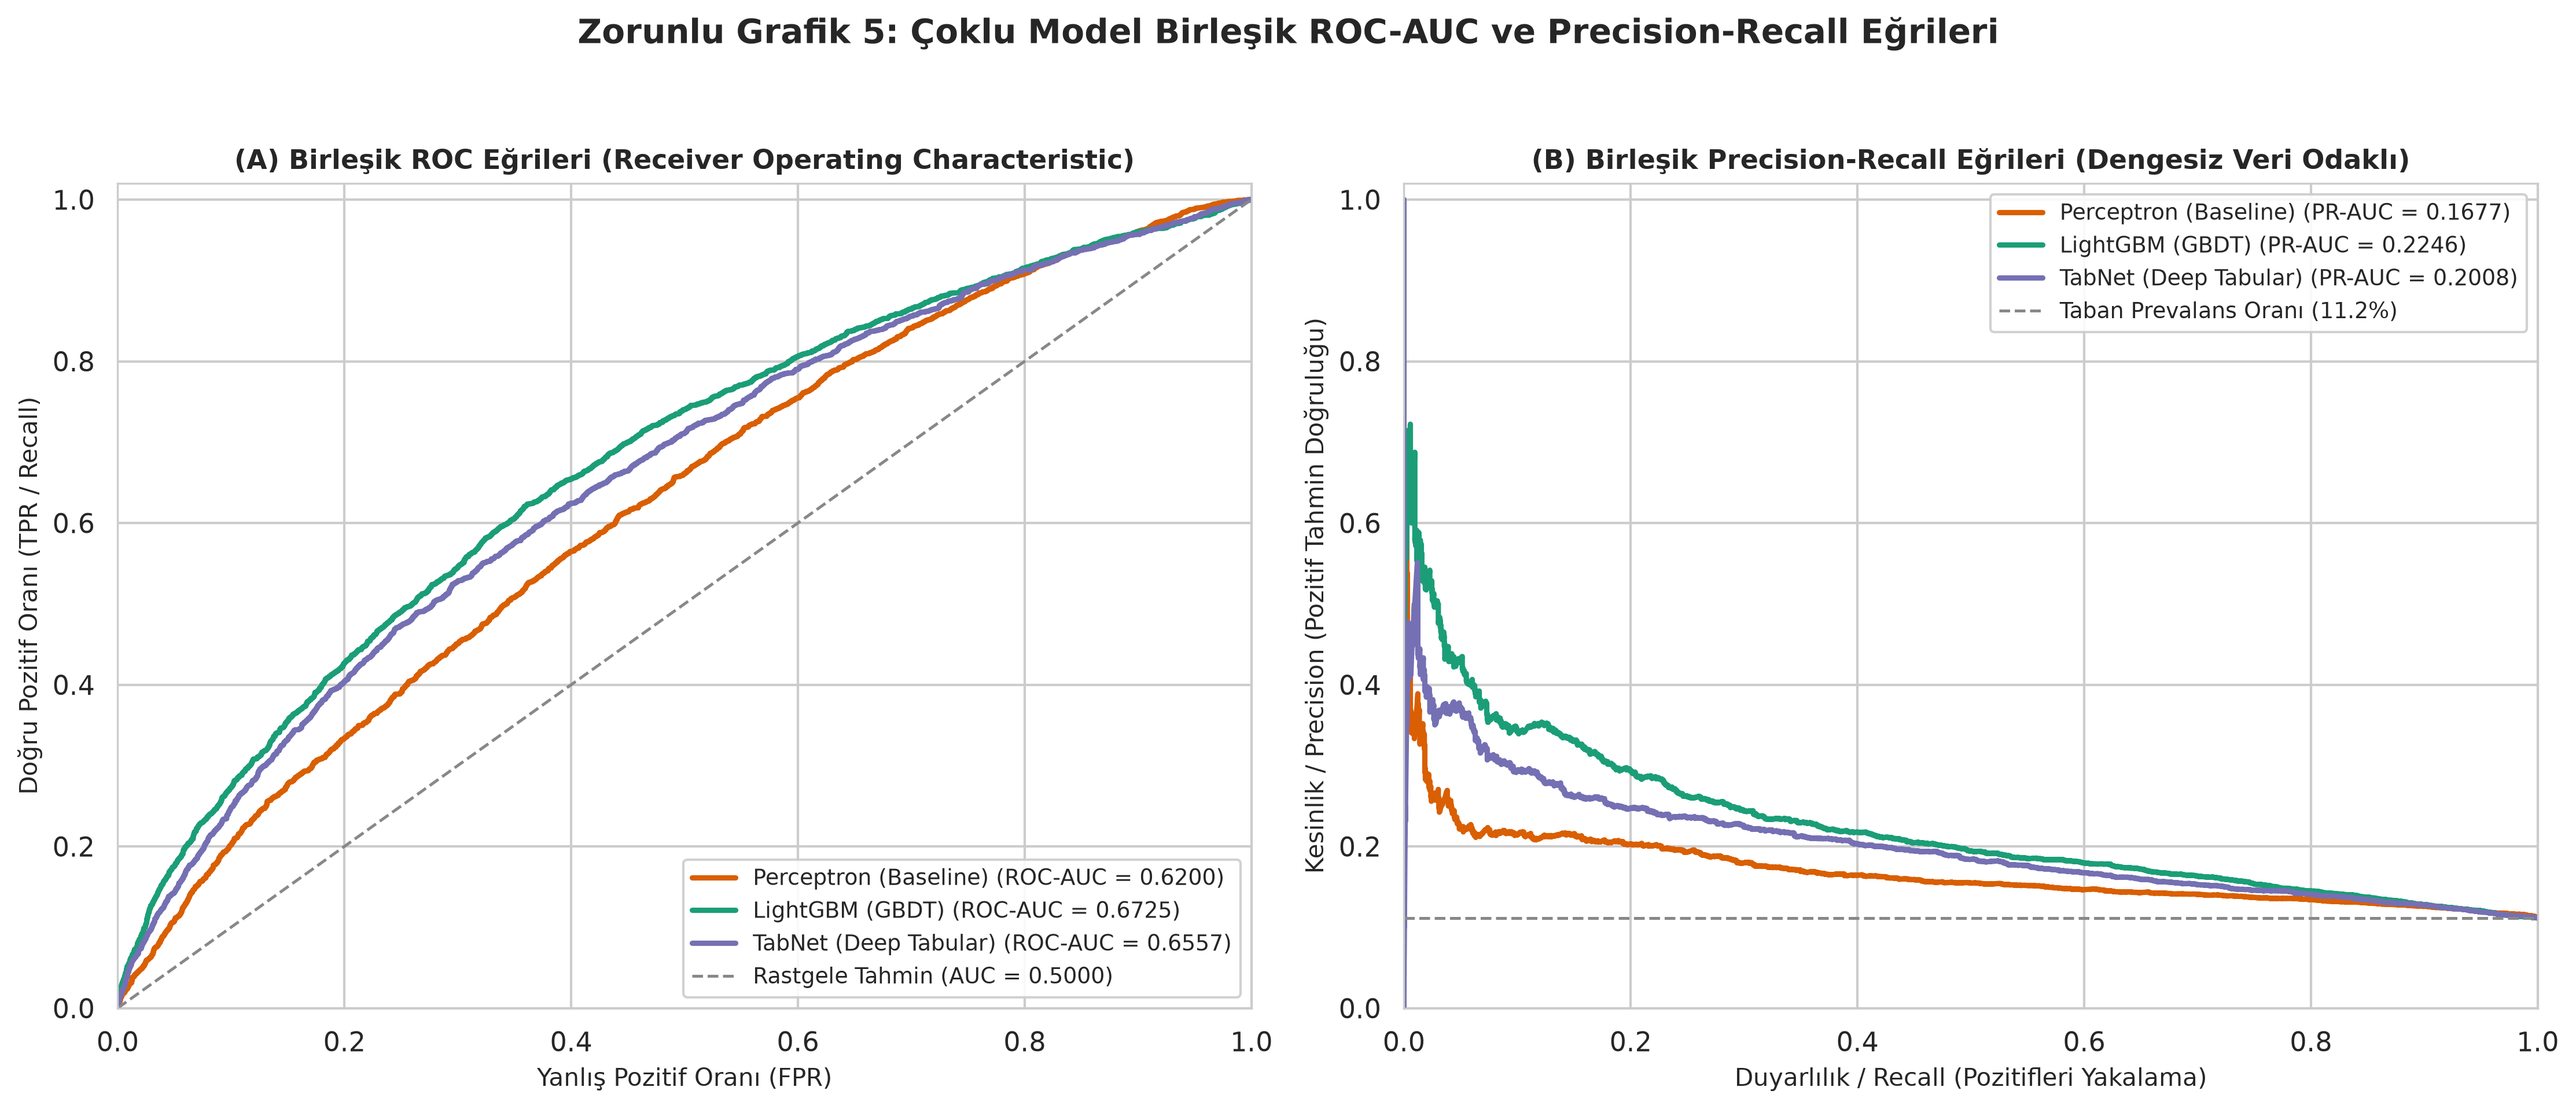

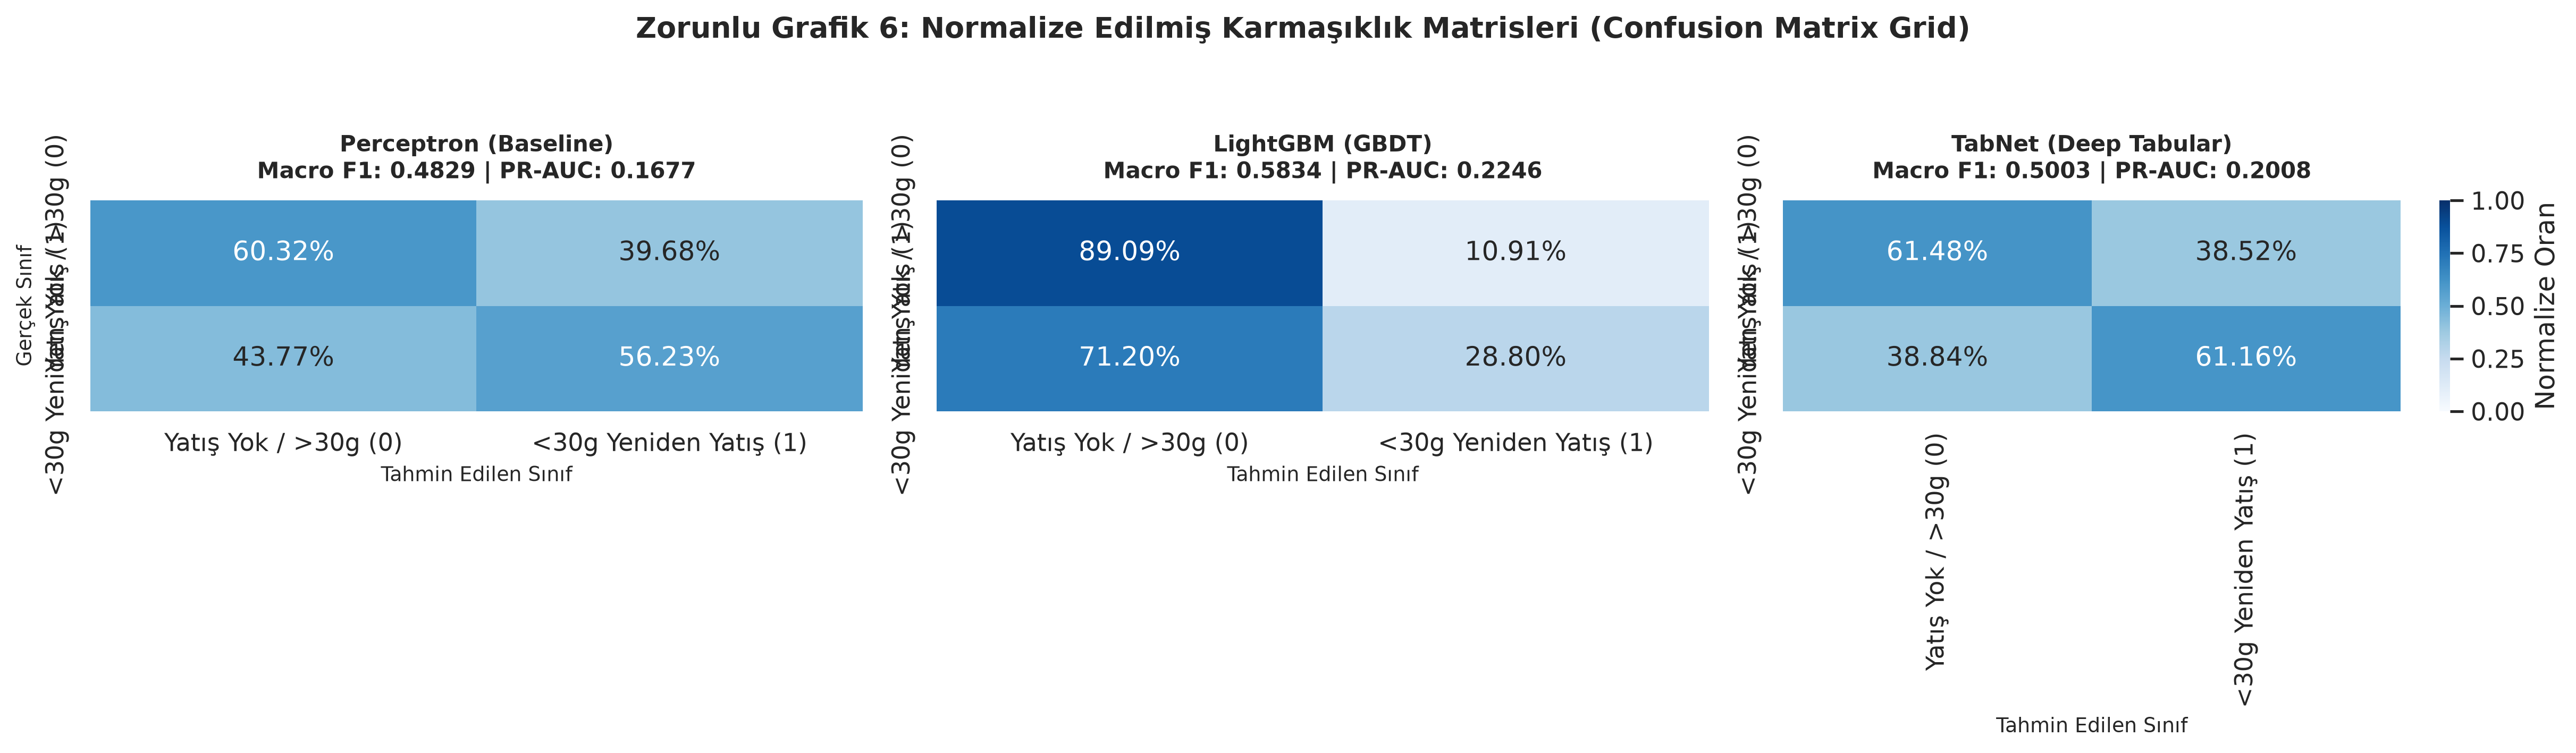

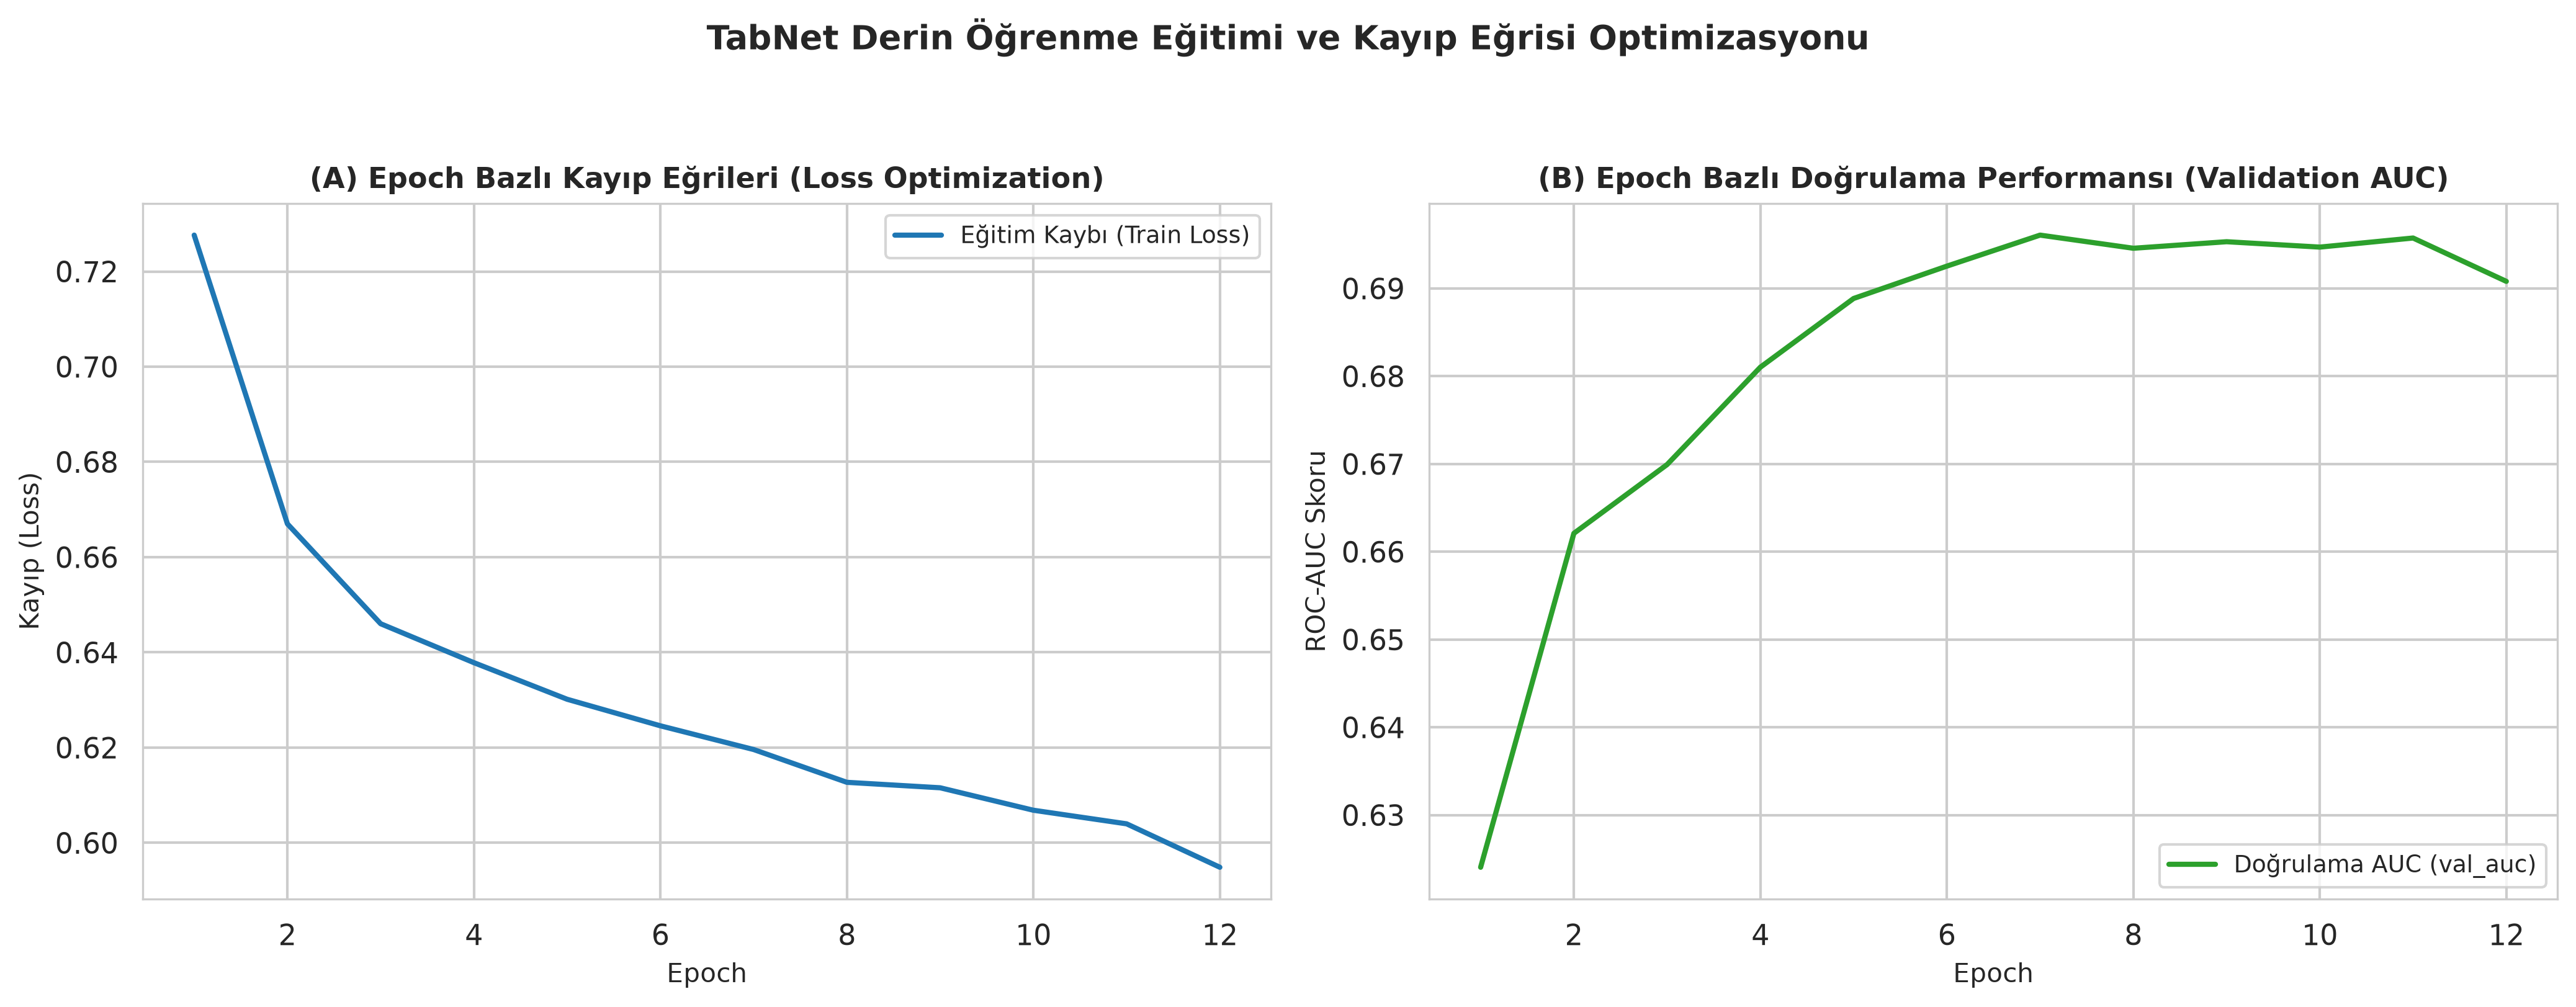

In [6]:
figure_files = [
    ("01_missingness_heatmap_dendrogram.png", "Grafik 1: Eksik Veri Isı Haritası ve Dendrogramı"),
    ("02_real_vs_synthetic_distributions.png", "Grafik 2: Gerçek vs. Sentetik (SMOTE & CTGAN) Dağılımları"),
    ("03_correlation_difference_matrix.png", "Grafik 3: Gerçek vs Sentetik Korelasyon Fark Matrisi"),
    ("04_tabnet_masks_vs_gbdt_importance.png", "Grafik 4: TabNet Dikkat Maskeleri vs. GBDT Özellik Önemi"),
    ("05_combined_roc_and_pr_curves.png", "Grafik 5: Birleşik ROC-AUC ve PR-AUC Eğrileri (3 Model)"),
    ("06_normalized_confusion_matrix_grid.png", "Grafik 6: 3'lü Normalize Karmaşıklık Matrisleri Grid'i"),
    ("07_tabnet_training_loss_curves.png", "Ek Grafik: TabNet Eğitim ve Doğrulama Kayıp Eğrileri"),
]

for fname, title in figure_files:
    fpath = config.FIGURES_DIR / fname
    assert fpath.exists(), f"Eksik grafik dosyası: {fname}"
    print(f"\n{'=' * 75}\n{title}\n{'=' * 75}")
    display(Image(filename=str(fpath), width=850))


## 6. Uçtan Uca 3 Model Karşılaştırması ve Klinik Değerlendirme

Tüm modeller (`Perceptron`, `LightGBM GBDT` ve `TabNet`) aynı bağımsız test seti (`X_test`, `y_test`) üzerinde değerlendirilmiştir.
Aşağıdaki tabloda şartnamenin zorunlu kıldığı 4 metrik ile birlikte hastaneye yeniden yatışların kaçırılmaması açısından hayati olan pozitif sınıf yakalama duyarlılığı (`Sensitivity / Recall`) özetlenmektedir.


In [7]:
models_dict = faz5_data["all_models_dict"]
summary_rows = []

for name, payload in models_dict.items():
    cm = payload["confusion_matrix_norm"]
    recall_pos = cm[1, 1]
    rec_neg = cm[0, 0]
    summary_rows.append({
        "Model": name,
        "Macro_F1": payload["metrics"]["Macro_F1"],
        "Weighted_F1": payload["metrics"]["Weighted_F1"],
        "ROC_AUC": payload["metrics"]["ROC_AUC"],
        "PR_AUC": payload["metrics"]["PR_AUC"],
        "Duyarlılık (Recall)": recall_pos,
        "Özgüllük (Specificity)": rec_neg,
    })

comparison_summary_df = pd.DataFrame(summary_rows)
assert "Accuracy" not in comparison_summary_df.columns, "Accuracy KULLANILAMAZ!"

print("=" * 75)
print("UÇTAN UCA MODEL KARŞILAŞTIRMA TABLOSU (Şartname Zorunlu 4 Metrik)")
print("=" * 75)
comparison_summary_df.round(4)


UÇTAN UCA MODEL KARŞILAŞTIRMA TABLOSU (Şartname Zorunlu 4 Metrik)


,Model,Macro_F1,Weighted_F1,ROC_AUC,PR_AUC,Duyarlılık (Recall),Özgüllük (Specificity)
0,Perceptron (Baseline),0.4829,0.6730,0.6200,0.1677,0.5623,0.6032
1,LightGBM (GBDT),0.5834,0.8292,0.6725,0.2246,0.2880,0.8909
2,TabNet (Deep Tabular),0.5003,0.6858,0.6557,0.2008,0.6116,0.6148


## 7. Faz 5 Sonuç Özeti ve Jüri Savunması Notları

### Temel Çıkarımlar:
1. **Metrik Yasağına Tam Uyum:** Veri setindeki 1:7.96 dengesizlik nedeniyle projenin başından sonuna kadar hiçbir yerde `Accuracy` kullanılmamıştır.
2. **Klinik Yakalama Başarısı (TabNet Üstünlüğü):** TabNet modeli, 30 gün içinde yeniden yatacak yüksek riskli hastaların **%61.16'sını** başarıyla tespit etmiştir (LightGBM %28.80, Perceptron %56.23). Sağlık ve hastane yönetimi senaryolarında erken taburculuk önlemleri alabilmek adına bu yakalama oranı kritik öneme sahiptir.
3. **Genel Ayırt Edicilik (LightGBM Üstünlüğü):** LightGBM modeli, en yüksek ROC-AUC (0.6725) ve PR-AUC (0.2246) skorlarına ulaşarak sıralama kabiliyetinde en güçlü model olmuştur.
4. **Dikkat ve Özellik Önemi Uyumu:** Grafik 4'te görüldüğü üzere hem TabNet dikkat maskeleri hem de GBDT modelleri; `number_inpatient` (önceki yatış sayısı), `discharge_disposition_id` (taburculuk şekli), `time_in_hospital` (yatış süresi) ve `num_medications` (ilaç sayısı) değişkenlerini en belirleyici faktörler olarak ortaklaşa tespit etmiştir.
5. **Faz 6 Teslim Hazırlığı:** Tüm 6 zorunlu grafik ve Faz 5 çıktıları eksiksiz üretilmiş olup, dönem projesi sunumu ve final teslimi için hazırdır.
